# Unsupervised Topic Discovery in Cambodian Reddit Discussion

# Required Libraries


In [1]:
# !pip install sentence-transformers umap-learn hdbscan langdetect scikit-learn seaborn


In [2]:
# !pip uninstall tensorflow keras umap-learn -y

# !pip install tensorflow==2.19 keras==3.13.2 umap-learn==0.5.11

In [3]:


import re
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import nltk
from langdetect import detect, LangDetectException
from sentence_transformers import SentenceTransformer
from sklearn.preprocessing import normalize
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.feature_extraction import _stop_words
from sklearn.metrics.pairwise import cosine_similarity
import umap
import hdbscan

# %matplotlib inline
# pd.set_option("display.max_colwidth", 100)
print("All imports successful.")

/Users/lengbunvyrak/Desktop/Spring 26'/ITM390/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


All imports successful.


# Loading the Dataset

In [4]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("bwandowando/reddit-rcambodia-subreddit-dataset-2026")

# List files in the downloaded directory to find the correct filename
print(f"Files in the downloaded dataset directory: {os.listdir(path)}")

# Construct the full path to the CSV file using os.path.join for robustness
file_name = 'cambodia_subreddit_comments.csv' # Assuming this is the correct file name
full_file_path = os.path.join(path, file_name)

# import the data into the environment
data = pd.read_csv(full_file_path)
data.head(5)

100%|██████████| 1.12G/1.12G [03:50<00:00, 5.22MB/s]

Extracting files...


Files in the downloaded dataset directory: ['cambodia_subreddit_images_15', 'cambodia_subreddit_images_12', 'cambodia_subreddit_images_13', 'cambodia_subreddit_images_14', 'cambodia_subreddit_images_07', 'cambodia_subreddit_images_09', 'cambodia_subreddit_images_08', 'cambodia_subreddit_images_01', 'cambodia_subreddit_images_06', 'cambodia_subreddit_images_20', 'cambodia_subreddit_images_18', 'cambodia_subreddit_images_11', 'cambodia_subreddit_images_16', 'cambodia_subreddit_images_17', 'cambodia_subreddit_images_10', 'cambodia_subreddit_images_19', 'cambodia_subreddit_images_03', 'cambodia_subreddit_images_04', 'cambodia_subreddit_threads.csv', 'cambodia_subreddit_images_05', 'cambodia_subreddit_images_02', 'cambodia_subreddit_comments.csv']


,author,body,created_utc,distinguished,edited,comment_id,is_submitter,parent_id,score,stickied,thread_id,version
0,1c45eee0-04dc-5929-a363-1012a1693ed0,You can find chamomile tea at lucky supermarket,2026-04-25 18:37:37,NaN,1970-01-01 00:00:00,efd1f427-70bd-5a23-a05a-9ad1c25bd2ad,False,1bc45abe-83d8-57ad-827a-07060b34a87c,1,False,1bc45abe-83d8-57ad-827a-07060b34a87c,1
1,b90457d3-dc47-5308-b368-d51500553177,To have the country that you love like your on...,2026-04-25 18:21:40,NaN,1970-01-01 00:00:00,94a4c26b-5f8f-5809-b4ef-153af477b1cb,False,7d5aa528-cc6a-549e-a1dc-b21c65fd49fb,1,False,7d5aa528-cc6a-549e-a1dc-b21c65fd49fb,1
2,9cbd5a09-e121-5815-99b9-68c01a3ab76a,"He got a point tho, if you’re Khmer and not Ca...",2026-04-25 18:14:03,NaN,1970-01-01 00:00:00,9d772f56-1020-5a1f-8d1e-b7ca9e3c9d4e,False,c2574780-9829-5fd4-99f0-888fcd4df9a6,1,False,40b77962-7c33-508f-8f08-58da1275b254,1
3,bb7ad8c0-979e-502d-a2ba-d3b35a79b3b4,I promise you....98% of the jobs that you have...,2026-04-25 17:48:08,NaN,1970-01-01 00:00:00,dee1b04e-a045-5384-8621-babb8e353aac,False,beaf683a-b009-5c62-818d-5a9d77dfb95f,1,False,9f472fc1-315d-5d27-890f-2b397ea17cd9,1
4,fc05f8ac-ad48-5967-b852-8cc55ef7f31a,Will some 25 year old dudes get away from this?,2026-04-25 17:24:28,NaN,1970-01-01 00:00:00,ae984ce2-483c-56ef-88d1-0afaf81873d1,False,40b77962-7c33-508f-8f08-58da1275b254,0,False,40b77962-7c33-508f-8f08-58da1275b254,1


# Data Preprocessing and Preparation

In [13]:
data.shape

(26584, 14)

In [14]:
data["body"]

0         You can find chamomile tea at lucky supermarket 
1        To have the country that you love like your on...
2        He got a point tho, if you’re Khmer and not Ca...
3        I promise you....98% of the jobs that you have...
4          Will some 25 year old dudes get away from this?
                               ...                        
26579                                            [removed]
26580           Do not attack Thai people or the business.
26581    Worst case scenario, what is Vietnamese policy...
26582    I’d also add that if you can, please also supp...
26583           I'm here and this is excellent information
Name: body, Length: 26584, dtype: str

In [15]:
# We want to query for the body with no context or detail is removed
non_usable_data = data.query('body == "[removed]"')

cleaned_data = data.drop(non_usable_data.index)

print(data.shape)
print(cleaned_data.shape)

print(data.shape[0] - cleaned_data.shape[0])

(26584, 14)
(26287, 14)
297


In [16]:
raw_data = cleaned_data.loc[:, ['body']]
raw_data

,body
0,You can find chamomile tea at lucky supermarket
1,To have the country that you love like your on...
2,"He got a point tho, if you’re Khmer and not Ca..."
3,I promise you....98% of the jobs that you have...
4,Will some 25 year old dudes get away from this?
...,...
26578,We've created a megathread for all posts about...
26580,Do not attack Thai people or the business.
26581,"Worst case scenario, what is Vietnamese policy..."
26582,"I’d also add that if you can, please also supp..."


In [17]:
raw_data[13:18]

,body
13,And what about the expat specimen? How many of...
14,get somebody else to do it 🫶🏽
15,I'm a ukrainian currently living in Cambodia. ...
16,Ok.
17,I have a Khmer friend in a reputable job and s...


# Data Cleaning

In [18]:
ENGLISH_STOP_WORDS = set(_stop_words.ENGLISH_STOP_WORDS)


CUSTOM_STOPWORDS = [
    "just", "like", "im", "dont", "get", "got", "know",
    "think", "good", "really", "people", "want", "need",
    "going", "make", "time", "way", "thing", "things",
    # Reddit-specific
    "post", "comment", "sub", "subreddit", "reddit",
    "upvote", "downvote", "karma", "moderator", "mod"
]

JUNK_KEYWORDS = [
    "bot", "mod", "subreddit", "removed", "deleted",
    "rules", "familiarize", "action performed", "moderator",
    "compose", "message", "reminder", "automoderator",
    'redd', 'webp', 'https preview', 'preview', 'width', 
    'auto webp', 'preview redd', 'format', 'https', 'auto',
    'deleted deleted', 'deleted', 'deleted removed', 'removed deleted',
    'removed', 'dictionary', 'lost', 'https', 'plants', 'megathread', 
    'did', 'does', 'whats', 'mean', 'right', 'lol', 
]

allstopwords = list(ENGLISH_STOP_WORDS) + CUSTOM_STOPWORDS + JUNK_KEYWORDS


def expand_contractions(text):
    contractions = {
        "don't": "do not",
        "doesn't": "does not",
        "didn't": "did not",
        "can't": "cannot",
        "won't": "will not",
        "i'm": "i am",
        "it's": "it is",
        "you're": "you are",
        "they're": "they are",
        "we're": "we are"
    }

    for k, v in contractions.items():
        text = text.replace(k, v)

    return text

def remove_reddit_artifacts(text):
    text = re.sub(r'\[deleted\]|\[removed\]', '', text)
    text = re.sub(r'r/\w+', '', text)
    text = re.sub(r'u/\w+', '', text)
    return text

def remove_urls(text):
    return re.sub(r'http\S+|www\.\S+', '', text)

def remove_markdown(text):
    text = re.sub(r'\*\*|__|~~|`', '', text)
    text = re.sub(r'^>.*$', '', text, flags=re.MULTILINE)
    text = re.sub(r'#{1,6}\s', '', text)
    return text

def normalize_whitespace(text):
    return re.sub(r'\s+', ' ', text).strip()

def clean_special_symbol(text):
  text = re.sub(r'[^\w\s]', '', text)
  text = re.sub(r'\s+', ' ', text)
  return text.strip()

def clean_junk_words(text):
    tokens = text.split()

    cleaned_tokens = []
    for token in tokens:
        # remove short tokens
        if len(token) <= 2:
            continue
        
        # remove stopwords
        if token in CUSTOM_STOPWORDS:
            continue
        
        # remove tokens with digits
        if any(char.isdigit() for char in token):
            continue
        
        cleaned_tokens.append(token)

    return " ".join(cleaned_tokens)


def clean_text(text):

    text = str(text).lower()

    # 1. Expand contractions FIRST
    text = expand_contractions(text)

    # 2. Remove Reddit-specific junk
    text = remove_reddit_artifacts(text)

    # 3. Remove URLs
    text = remove_urls(text)

    # 4. Remove markdown
    text = remove_markdown(text)

    # 5. Remove boilerplate
    text = re.sub(r'subredditmessagecomposeto\S*', '', text, flags=re.IGNORECASE)
    text = re.sub(r'message/compose\S*', '', text, flags=re.IGNORECASE)

    BOILERPLATE = [
        r'please familiarize yourself with.*?rules',
        r'your post has been removed',
        r'action performed.*?bot',
        r'i am a bot.*',
        r'contact the moderators',
        r'this is a reminder.*',
        r'please read the rules',
        r'if you have questions.*contact',
    ]
    for pattern in BOILERPLATE:
        text = re.sub(pattern, '', text, flags=re.IGNORECASE | re.DOTALL)

    # 6. Remove special characters
    text = clean_special_symbol(text)

    # 7. Normalize whitespace
    text = normalize_whitespace(text)

    # 8. Remove junk words (FINAL STEP)
    text = clean_junk_words(text)

    return text

def detect_language(text):
    try:
        return detect(text)
    except LangDetectException:
        return "unknown"

print("Cleaning functions defined.")

Cleaning functions defined.


In [19]:
df_cleaned = raw_data.copy()
df_cleaned["cleaned_text"] = df_cleaned["body"].apply(clean_text)

In [20]:
# Remove very shorta / low-information posts
df_cleaned["text_length"] = df_cleaned["cleaned_text"].str.split().str.len()

df_cleaned = df_cleaned[df_cleaned["text_length"] > 5].copy()

# Reset index to avoid downstream mismatch
df_cleaned.reset_index(drop=True, inplace=True)

In [21]:
df_cleaned

,body,cleaned_text,text_length
0,You can find chamomile tea at lucky supermarket,you can find chamomile tea lucky supermarket,7
1,To have the country that you love like your on...,have the country that you love your only home ...,14
2,"He got a point tho, if you’re Khmer and not Ca...",point tho youre khmer and not cambodian then y...,22
3,I promise you....98% of the jobs that you have...,promise the jobs that you have interviewed for...,19
4,Will some 25 year old dudes get away from this?,will some year old dudes away from this,8
...,...,...,...
20691,Thanks for all the information to all traveler...,thanks for all the information all travelerswh...,23
20692,"To enter Vietnam, you need a pre-arranged visa...",enter vietnam you prearranged visa hold passpo...,12
20693,We've created a megathread for all posts about...,weve created megathread for all posts about th...,23
20694,"Worst case scenario, what is Vietnamese policy...",worst case scenario what vietnamese policy lan...,19


# Feature Extraction

## Sentence Embedding (Multilingual Transformer)

In [22]:
from langdetect import detect, LangDetectException

def detect_language(text):
  try:
    return detect(text)
  except LangDetectException:
    return "UNK"


df_cleaned["language"] = df_cleaned["cleaned_text"].apply(detect_language)
print(df_cleaned["language"].value_counts())

# Keep only English posts
df_cleaned = df_cleaned[df_cleaned["language"] == "en"].copy()

df_cleaned.reset_index(drop=True, inplace=True)



language
en     20497
fr        35
af        19
no        17
da        16
ca        15
it        14
cy        13
nl        11
id         9
de         9
es         7
tl         7
sv         6
ro         5
fi         4
UNK        3
so         3
et         2
tr         2
th         1
ru         1
Name: count, dtype: int64


In [23]:
df = df_cleaned.copy()
df = df.reset_index(drop=True)
texts = df['cleaned_text'].tolist()

print(f"df rows: {len(df)}, texts: {len(texts)}")  # must match
assert len(df) == len(texts), "Mismatch before encoding!"

df rows: 20497, texts: 20497


In [24]:
texts

['you can find chamomile tea lucky supermarket',
 'have the country that you love your only home afraid joint the air force',
 'point tho youre khmer and not cambodian then you probably worry about getting drafted yall lowkey butt hurt even though hes right',
 'promise the jobs that you have interviewed for have looked your social mediaat least the extent that they can',
 'will some year old dudes away from this',
 'will difficult but doable you both effort learn the others language either you unwilling that then that person does not care enough the relationship work you not both fluent but you least both have few hundred words the others language equally important question how either both parties children feel about they are strongly opposed the strain could eventually pull the marriage apart answer your specific question she will definitely encounter prejudice from other cambodians find that cambodians especially those over general rule are extremely concerned about saving face depen

In [25]:
model = SentenceTransformer('sentence-transformers/all-mpnet-base-v2')

# Always re-encode from current texts — no cache
print(f"Encoding {len(texts)} posts with {model}...")

embeddings = model.encode(
    texts,
    batch_size=64,
    convert_to_numpy=True,
    show_progress_bar=True
)

os.makedirs("data", exist_ok=True)
np.save("data/embedding.npy", embeddings)

print(f"Done. embeddings.shape = {embeddings.shape}")
assert embeddings.shape[0] == len(texts), (
    f"Mismatch: {embeddings.shape[0]} embeddings vs {len(texts)} texts"
)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 8928.16it/s]
MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Encoding 20497 posts with SentenceTransformer(
  (0): Transformer({'max_seq_length': 384, 'do_lower_case': False, 'architecture': 'MPNetModel'})
  (1): Pooling({'word_embedding_dimension': 768, 'pooling_mode_cls_token': False, 'pooling_mode_mean_tokens': True, 'pooling_mode_max_tokens': False, 'pooling_mode_mean_sqrt_len_tokens': False, 'pooling_mode_weightedmean_tokens': False, 'pooling_mode_lasttoken': False, 'include_prompt': True})
  (2): Normalize()
)...


Batches: 100%|██████████| 321/321 [01:12<00:00,  4.45it/s]

Done. embeddings.shape = (20497, 768)


In [26]:
embeddings.shape

(20497, 768)

In [27]:
len(texts)

20497

## Embedding Normalization

In [28]:
from torch import embedding
embeddings_norm = normalize(embeddings, norm="l2")

sample_norms = np.linalg.norm(embeddings_norm[:5], axis=1)
print(f"Sample L2 norms (should all be 1.0): {sample_norms.round(4)}")


Sample L2 norms (should all be 1.0): [1. 1. 1. 1. 1.]


## Dimension Reduction

In [29]:
# Here we perform high-dim for clustering

print(f"Running UMAP: {embeddings_norm.shape[1]}D → 70D")

reducer = umap.UMAP(
    n_neighbors=50,
    n_components=70,
    min_dist=0.1,
    metric="cosine",
    random_state=42,
    verbose=True
)

embeddings_reduced = reducer.fit_transform(embeddings_norm)
print(f"\nReduced shape: {embeddings_reduced.shape}")

/Users/lengbunvyrak/Desktop/Spring 26'/ITM390/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Running UMAP: 768D → 70D
UMAP(angular_rp_forest=True, metric='cosine', n_components=70, n_jobs=1, n_neighbors=50, random_state=42, verbose=True)
Sun Apr 26 21:57:10 2026 Construct fuzzy simplicial set
Sun Apr 26 21:57:10 2026 Finding Nearest Neighbors
Sun Apr 26 21:57:10 2026 Building RP forest with 12 trees
Sun Apr 26 21:57:12 2026 NN descent for 14 iterations
	 1  /  14
	 2  /  14
	 3  /  14
	 4  /  14
	Stopping threshold met -- exiting after 4 iterations
Sun Apr 26 21:57:23 2026 Finished Nearest Neighbor Search
Sun Apr 26 21:57:23 2026 Construct embedding


Epochs completed:   4%| ▍          8/200 [00:00]

	completed  0  /  200 epochs


Epochs completed:  12%| █▏         23/200 [00:01]

...

	completed  160  /  200 epochs


Epochs completed:  92%| █████████▏ 183/200 [00:12]

	completed  180  /  200 epochs


Epochs completed: 100%| ██████████ 200/200 [00:13]

Sun Apr 26 21:57:38 2026 Finished embedding

Reduced shape: (20497, 70)


In [30]:
# Here will perform another clustering but at only 2D for visualization projection
reducer_2d = umap.UMAP(
    n_neighbors = 15,
    n_components = 2,
    min_dist = 0.1,
    metric="cosine",
    random_state=42

  )
embeddings_2d = reducer_2d.fit_transform(embeddings_reduced)
print(f"2D shape: {embeddings_2d.shape}")


/Users/lengbunvyrak/Desktop/Spring 26'/ITM390/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


2D shape: (20497, 2)


# Model Developemnt

## Clustering

In [31]:
# ── Clustering ───────────────────────────────────────────────────────────────
clusterer = hdbscan.HDBSCAN(
    min_cluster_size=50,
    min_samples=5,
    cluster_selection_method="leaf",      # eom gives fewer, broader topics vs leaf
    cluster_selection_epsilon=0.05,       # merges near-duplicate clusters
    metric="euclidean",
    prediction_data=True
)

labels = clusterer.fit_predict(embeddings_reduced)

# ── Assign back to df
df["cluster"] = labels
cluster_docs = df.groupby("cluster")["cleaned_text"].apply(lambda x: " ".join(x))

# ── Diagnostics ──────────────────────────────────────────────────────────────
n_clusters   = len(set(labels)) - (1 if -1 in labels else 0)
n_noise      = (labels == -1).sum()
noise_ratio  = n_noise / len(labels)
coverage     = 1 - noise_ratio

print(f"Total documents  : {len(labels)}")
print(f"Clusters found   : {n_clusters}")
print(f"Noise points     : {n_noise} ({noise_ratio:.1%} of corpus)")
print(f"Corpus coverage  : {coverage:.1%}")
print(f"\nTop 10 cluster sizes:")
print(pd.Series(labels[labels != -1]).value_counts().head(10).to_string())

# ── Cluster size distribution ─────────────────────────────────────────────────
cluster_sizes = pd.Series(labels[labels != -1]).value_counts()
print(f"\nSmallest cluster : {cluster_sizes.min()} docs")
print(f"Largest cluster  : {cluster_sizes.max()} docs")
print(f"Median cluster   : {cluster_sizes.median():.0f} docs")

Total documents  : 20497
Clusters found   : 59
Noise points     : 13021 (63.5% of corpus)
Corpus coverage  : 36.5%

Top 10 cluster sizes:
24    574
27    411
43    340
37    332
36    300
42    279
35    276
54    253
13    212
34    207

Smallest cluster : 51 docs
Largest cluster  : 574 docs
Median cluster   : 85 docs


In [32]:
soft_clusters = hdbscan.all_points_membership_vectors(clusterer)
# For each noise point, assign to cluster with highest probability
labels_clean = np.argmax(soft_clusters, axis=1)

In [33]:

labels_clean = labels.copy()
unique_clusters = [l for l in sorted(set(labels)) if l != -1]

# Compute centroids in normalized embedding space
centroids = np.array([
    embeddings_norm[labels == c].mean(axis=0)
    for c in unique_clusters
])

noise_mask = labels_clean == -1
if noise_mask.sum() > 0:
    noise_embeddings = embeddings_norm[noise_mask]
    sims = cosine_similarity(noise_embeddings, centroids)
    best = sims.argmax(axis=1)
    threshold = 0.5  # tune this

    best_scores = sims.max(axis=1)

    labels_clean[noise_mask] = np.where(
        best_scores > threshold,
        np.array(unique_clusters)[best],
        -1
    )
    
    print(f"Reassigned {noise_mask.sum()} noise points to nearest cluster.")

print(f"Noise remaining: {(labels_clean == -1).sum()}")

Reassigned 13021 noise points to nearest cluster.
Noise remaining: 7161


## Labeling

In [34]:
vectorizer = TfidfVectorizer(
    ngram_range  = (1, 2),
    max_df=0.8,
    min_df=10,
    max_features = 10000,
    stop_words   = allstopwords
)

tfidf_matrix = vectorizer.fit_transform(cluster_docs)
feature_names = vectorizer.get_feature_names_out()

# Extract top N words per cluster
cluster_results = []
for i, cluster_id in enumerate(cluster_docs.index):
    top_idx  = tfidf_matrix[i].toarray().flatten().argsort()[-10:][::-1]
    top_words = [feature_names[j] for j in top_idx]
    cluster_results.append({
        "cluster"   : cluster_id,
        "size"      : (labels_clean == cluster_id).sum(),
        "top_words" : top_words,
        "label"     : " | ".join(top_words[:3])
    })

cluster_df = pd.DataFrame(cluster_results).sort_values("size", ascending=False).reset_index(drop=True)
cluster_df[["cluster", "label", "size", "top_words"]]

/Users/lengbunvyrak/Desktop/Spring 26'/ITM390/.venv/lib/python3.11/site-packages/sklearn/feature_extraction/text.py:411: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['action', 'performed'] not in stop_words.
  warnings.warn(


,cluster,label,size,top_words
0,-1,cambodia | thai | thailand,7161,"[cambodia, thai, thailand, khmer, country, cam..."
1,55,cambodia | corruption | peace,815,"[cambodia, corruption, peace, country, educati..."
2,57,thailand | thai | cambodia,682,"[thailand, thai, cambodia, border, military, h..."
3,24,schools | school | teacher,606,"[schools, school, teacher, english, job, educa..."
4,13,visa | cambodia | passport,453,"[visa, cambodia, passport, arrival, entry, cam..."
5,35,beer | bar | drink,431,"[beer, bar, drink, riverside, street, night, f..."
6,36,rent | hotel | month,427,"[rent, hotel, month, land, room, price, market..."
7,27,thanks | thank | app,422,"[thanks, thank, app, ill, appreciate, info, ch..."
8,37,food | restaurant | khmer,420,"[food, restaurant, khmer, rice, eat, coffee, r..."
9,45,cambodia | vietnam | visit,410,"[cambodia, vietnam, visit, food, love, friendl..."


In [35]:
def is_junk_cluster(top_words: list) -> bool:
    top_words_flat = " ".join(top_words).lower()
    return any(kw in top_words_flat for kw in JUNK_KEYWORDS)


cluster_df["is_junk"] = cluster_df["top_words"].apply(is_junk_cluster)

# Remove junk cluster posts from dataframe
junk_cluster_ids = cluster_df[cluster_df["is_junk"]]["cluster"].tolist()
df_clean = df[~df["cluster"].isin(junk_cluster_ids)].reset_index(drop=True)

print(f"Junk clusters removed : {len(junk_cluster_ids)}")
print(f"Posts remaining       : {len(df_clean)}")
print(cluster_df[["cluster", "label", "size", "is_junk"]])

Junk clusters removed : 1
Posts remaining       : 20157
    cluster                             label  size  is_junk
0        -1        cambodia | thai | thailand  7161    False
1        55     cambodia | corruption | peace   815    False
2        57        thailand | thai | cambodia   682    False
3        24        schools | school | teacher   606    False
4        13        visa | cambodia | passport   453    False
5        35                beer | bar | drink   431    False
6        36              rent | hotel | month   427    False
7        27              thanks | thank | app   422    False
8        37         food | restaurant | khmer   420    False
9        45        cambodia | vietnam | visit   410    False
10       54  rouge | khmer rouge | vietnamese   409    False
11       43          posts | claims | sources   387     True
12       42        khmer | english | language   346    False
13       44       cambodia | siem | siem reap   328    False
14       49           kampot 

In [36]:
cluster_df['label'][:10]

0       cambodia | thai | thailand
1    cambodia | corruption | peace
2       thailand | thai | cambodia
3       schools | school | teacher
4       visa | cambodia | passport
5               beer | bar | drink
6             rent | hotel | month
7             thanks | thank | app
8        food | restaurant | khmer
9       cambodia | vietnam | visit
Name: label, dtype: str

# Model Evaluation

In [37]:
# WITHOUT noise (your current method)
mask = labels_clean != -1
score_no_noise = silhouette_score(embeddings_reduced[mask], labels_clean[mask])

# WITH noise (more honest)
score_with_noise = silhouette_score(embeddings_reduced, labels_clean)

print("Silhouette (no noise):", score_no_noise)
print("Silhouette (with noise):", score_with_noise)
eval_embeddings = embeddings_reduced[mask]
eval_labels = labels_clean[mask]

metrics = { 
    "n_clusters"               : int(len(unique_clusters)),
    "n_noise_original"         : int(n_noise),
    "noise_ratio_original"     : round(float(noise_ratio), 4),
    "silhouette_score"         : round(float(silhouette_score(eval_embeddings, eval_labels)), 4),
    "davies_bouldin_score"     : round(float(davies_bouldin_score(eval_embeddings, eval_labels)), 4),
    "calinski_harabasz_score"  : round(float(calinski_harabasz_score(eval_embeddings, eval_labels)), 4),
}

pd.DataFrame([metrics]).T.rename(columns={0: "value"})

Silhouette (no noise): 0.2417791485786438
Silhouette (with noise): -0.052951447665691376


,value
n_clusters,59.0000
n_noise_original,13021.0000
noise_ratio_original,0.6353
silhouette_score,0.2418
davies_bouldin_score,1.2346
calinski_harabasz_score,2564.9657


# Visualization

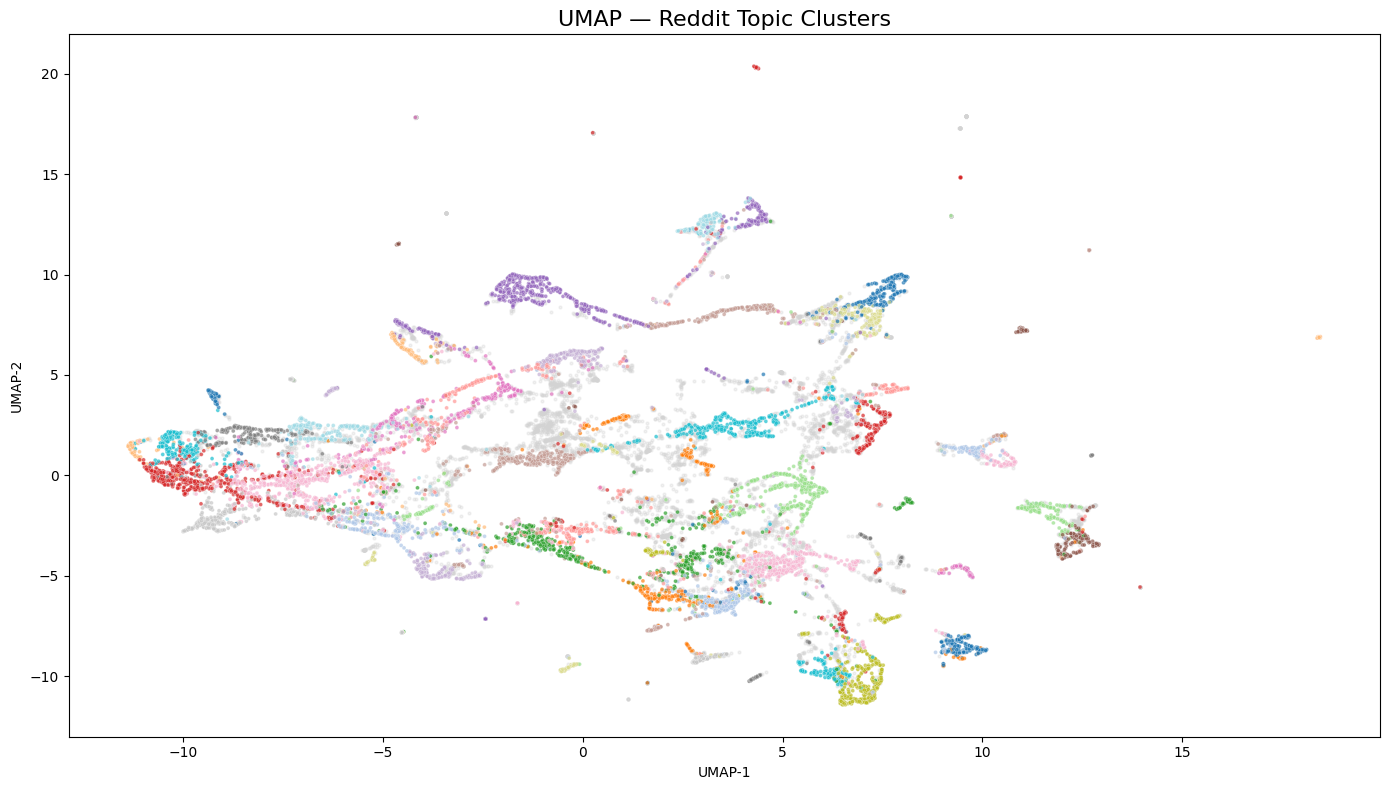

In [38]:
plot_df = pd.DataFrame({
    "x"       : embeddings_2d[:, 0],
    "y"       : embeddings_2d[:, 1],
    "cluster" : labels_clean.astype(str)
})

fig, ax = plt.subplots(figsize=(14, 8))

noise_df = plot_df[plot_df["cluster"] == "-1"]
data_df  = plot_df[plot_df["cluster"] != "-1"]

ax.scatter(noise_df["x"], noise_df["y"], c="lightgray", s=4, alpha=0.3, label="Noise")
sns.scatterplot(
    data=data_df, x="x", y="y", hue="cluster",
    palette="tab20", s=8, alpha=0.7, ax=ax, legend=False
)

ax.set_title("UMAP — Reddit Topic Clusters", fontsize=16)
ax.set_xlabel("UMAP-1"); ax.set_ylabel("UMAP-2")
plt.tight_layout()
plt.show()

# Exploratory Data Analysis

In [ ]:
print("=== Dataset Shape ===")
print(f"Rows: {data.shape[0]}, Columns: {data.shape[1]}")

print("\n=== Data Types ===")
print(data.dtypes)

print("\n=== Missing Values ===")
print(data.isnull().sum())

print("\n=== Sample of key columns ===")
data.head(5)

=== Dataset Shape ===
Rows: 26584, Columns: 12

=== Data Types ===
author             str
body               str
created_utc        str
distinguished      str
edited             str
comment_id         str
is_submitter      bool
parent_id          str
score            int64
stickied          bool
thread_id          str
version          int64
dtype: object

=== Missing Values ===
author               0
body                 0
created_utc          0
distinguished    26312
edited               0
comment_id           0
is_submitter         0
parent_id            0
score                0
stickied             0
thread_id            0
version              0
dtype: int64

=== Sample of key columns ===


,author,body,created_utc,distinguished,edited,comment_id,is_submitter,parent_id,score,stickied,thread_id,version
0,1c45eee0-04dc-5929-a363-1012a1693ed0,You can find chamomile tea at lucky supermarket,2026-04-25 18:37:37,NaN,1970-01-01 00:00:00,efd1f427-70bd-5a23-a05a-9ad1c25bd2ad,False,1bc45abe-83d8-57ad-827a-07060b34a87c,1,False,1bc45abe-83d8-57ad-827a-07060b34a87c,1
1,b90457d3-dc47-5308-b368-d51500553177,To have the country that you love like your on...,2026-04-25 18:21:40,NaN,1970-01-01 00:00:00,94a4c26b-5f8f-5809-b4ef-153af477b1cb,False,7d5aa528-cc6a-549e-a1dc-b21c65fd49fb,1,False,7d5aa528-cc6a-549e-a1dc-b21c65fd49fb,1
2,9cbd5a09-e121-5815-99b9-68c01a3ab76a,"He got a point tho, if you’re Khmer and not Ca...",2026-04-25 18:14:03,NaN,1970-01-01 00:00:00,9d772f56-1020-5a1f-8d1e-b7ca9e3c9d4e,False,c2574780-9829-5fd4-99f0-888fcd4df9a6,1,False,40b77962-7c33-508f-8f08-58da1275b254,1
3,bb7ad8c0-979e-502d-a2ba-d3b35a79b3b4,I promise you....98% of the jobs that you have...,2026-04-25 17:48:08,NaN,1970-01-01 00:00:00,dee1b04e-a045-5384-8621-babb8e353aac,False,beaf683a-b009-5c62-818d-5a9d77dfb95f,1,False,9f472fc1-315d-5d27-890f-2b397ea17cd9,1
4,fc05f8ac-ad48-5967-b852-8cc55ef7f31a,Will some 25 year old dudes get away from this?,2026-04-25 17:24:28,NaN,1970-01-01 00:00:00,ae984ce2-483c-56ef-88d1-0afaf81873d1,False,40b77962-7c33-508f-8f08-58da1275b254,0,False,40b77962-7c33-508f-8f08-58da1275b254,1


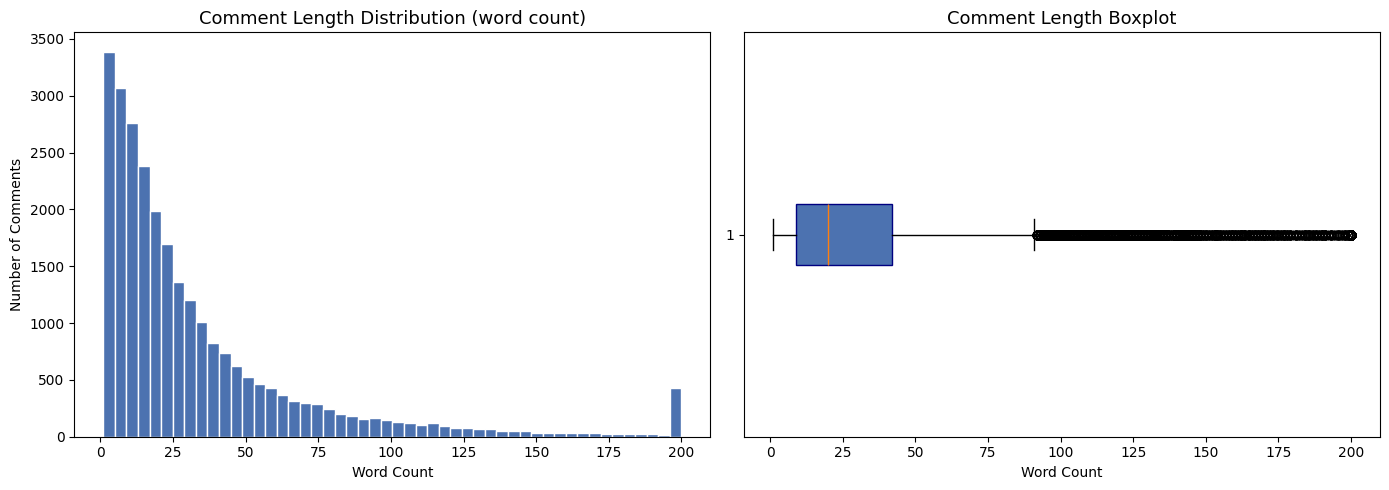

count    26584.00
mean        35.37
std         53.26
min          1.00
25%          9.00
50%         20.00
75%         42.00
max       1326.00
Name: word_count, dtype: float64


In [ ]:
data["word_count"] = data["body"].astype(str).apply(lambda x: len(x.split()))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].hist(data["word_count"].clip(upper=200), bins=50, color="#4C72B0", edgecolor="white")
axes[0].set_title("Comment Length Distribution (word count)", fontsize=13)
axes[0].set_xlabel("Word Count")
axes[0].set_ylabel("Number of Comments")

# Boxplot
axes[1].boxplot(data["word_count"].clip(upper=200), vert=False, patch_artist=True,
                boxprops=dict(facecolor="#4C72B0", color="navy"))
axes[1].set_title("Comment Length Boxplot", fontsize=13)
axes[1].set_xlabel("Word Count")

plt.tight_layout()
plt.show()

print(data["word_count"].describe().round(2))

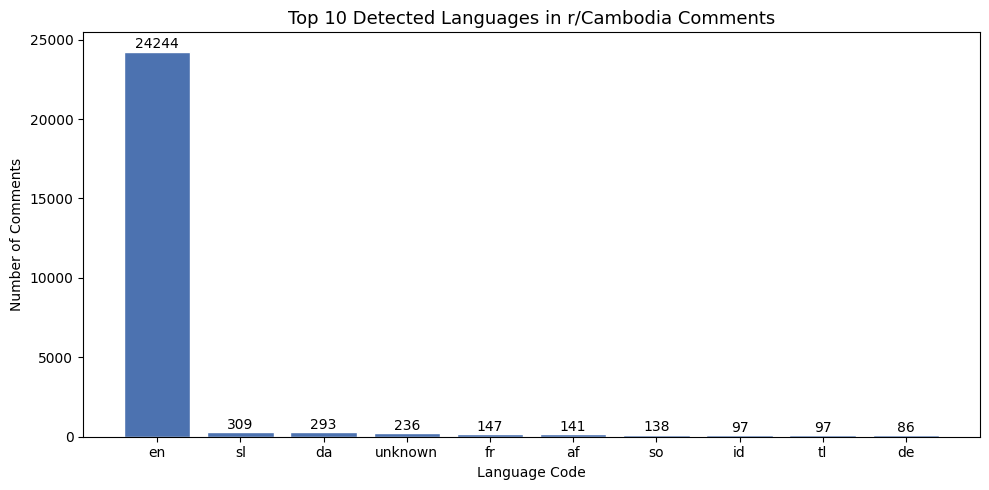

language
en         24244
sl           309
da           293
unknown      236
fr           147
af           141
so           138
id            97
tl            97
de            86
Name: count, dtype: int64


In [ ]:
from langdetect import detect, LangDetectException

def detect_language(text):
    try:
        return detect(str(text))
    except LangDetectException:
        return "unknown"

data["language"] = data["body"].apply(detect_language)

lang_counts = data["language"].value_counts().head(10)

plt.figure(figsize=(10, 5))
bars = plt.bar(lang_counts.index, lang_counts.values, color="#4C72B0", edgecolor="white")
plt.title("Top 10 Detected Languages in r/Cambodia Comments", fontsize=13)
plt.xlabel("Language Code")
plt.ylabel("Number of Comments")

for bar, val in zip(bars, lang_counts.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10,
             str(val), ha="center", va="bottom", fontsize=10)

plt.tight_layout()
plt.show()

print(lang_counts)

/Users/lengbunvyrak/Desktop/Spring 26'/ITM390/.venv/lib/python3.11/site-packages/sklearn/feature_extraction/text.py:411: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['action', 'performed'] not in stop_words.
  warnings.warn(


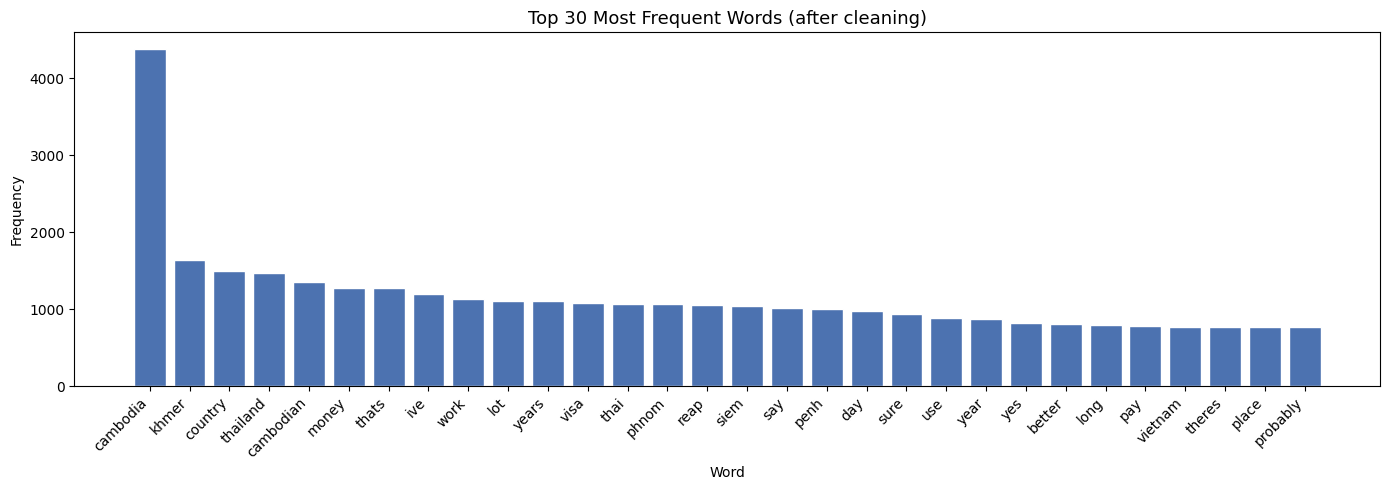

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

# Use cleaned texts
vectorizer_eda = CountVectorizer(
    stop_words= allstopwords,
    max_features=30,
    ngram_range=(1, 1)
)

X = vectorizer_eda.fit_transform(df_cleaned["cleaned_text"])
word_freq = pd.Series(
    X.toarray().sum(axis=0),
    index=vectorizer_eda.get_feature_names_out()
).sort_values(ascending=False)

plt.figure(figsize=(14, 5))
bars = plt.bar(word_freq.index, word_freq.values, color="#4C72B0", edgecolor="white")
plt.title("Top 30 Most Frequent Words (after cleaning)", fontsize=13)
plt.xlabel("Word")
plt.ylabel("Frequency")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()